In [1]:
# CM3 eval for historical SST trend

Based on https://github.com/COSIMA/cosima-recipes/blob/8a0205ec0c85d2d08fe94fb3acd901b18f392c37/Cooking-Lessons-101-Tutorials/Apply_function_to_every_gridpoint.ipynb

In [2]:
#parameters

### USER EDIT start
esm_file='/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json'
#'/g/data/ol01/access-om3-output/access-om3-025/MC_25km_jra_ryf-1.0-beta/experiment_datastore.json'
dpi=300

# papermill settings. *No need to modify these if running interactively.*
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory
nbname = None                          # notebook name


In [3]:
# Parameters
esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/get_cm3website-gogo/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PD-control/"
nbname = "SST_trend_global.ipynb"


In [4]:
import os  # always: the old parameters cell imported it, and notebooks use os.* (TOA_CRE does)
if not papermill:
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter

import matplotlib as mpl
%matplotlib inline
mpl.rcParams['figure.dpi'] = dpi

mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)


In [5]:
import numpy as np

from dask.distributed import Client

import xarray as xr
import cf_xarray as cfxr
import cf_xarray.units
import pint_xarray
from pint import application_registry as ureg
import intake

import matplotlib.pyplot as plt
import cmocean as cm
import scipy
import cartopy.crs as ccrs

In [6]:
COLUMNS_WITH_ITERABLES = [
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
]

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=COLUMNS_WITH_ITERABLES
)

In [7]:
sst_cm3 = datastore.search(variable="thetao", frequency="1mon").to_dask(
    xarray_open_kwargs = dict(
        chunks={"z_l": 1, "yh": -1, "xh": -1}, # Good for spatial operations, but not temporal
        decode_timedelta=True
    )
).thetao.isel(z_l=0).sel(time=slice('1981','2000')).compute()

In [8]:
coords = datastore.search(variable=["geolat", "geolon"]).to_dask(
    xarray_open_kwargs = dict(
        use_cftime=True
    )
).compute()
coords = coords.fillna(0.0)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:316: ConcatenationWarning: Attempting to concatenate datasets without valid dimension coordinates: retaining only first dataset. Request valid dimension coordinate to silence this warning.
  warnings.warn(


In [9]:
def calc_sst_trend(sst, freq):
    '''
    freq = monthly = 12, daily = 365
    '''

    y = sst.data
    n = y.shape[0]
    x = np.arange(n) / freq
    trend_data = n * (x[:, None, None] * y).sum(axis=0) - x.sum() * y.sum(axis=0)
    trend_data /= n * (x**2).sum() - x.sum()**2

    sst_trend = sst.isel(time=0).copy()
    sst_trend.data[:] = trend_data

    sst_trend = sst_trend.assign_coords(coords)

    return sst_trend

In [10]:
sst_trend_cm3_monthly = calc_sst_trend(sst_cm3.sel(time=slice('1981','2000')), 12)

Saved /g/data/tm70/cyb561/repos/get_cm3website-gogo/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PD-control/mkmd/SST_trend_global_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/get_cm3website-gogo/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PD-control/mkmd/SST_trend_global.md


Lines appended to /g/data/tm70/cyb561/repos/get_cm3website-gogo/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PD-control/mkmd/SST_trend_global.md successfully.


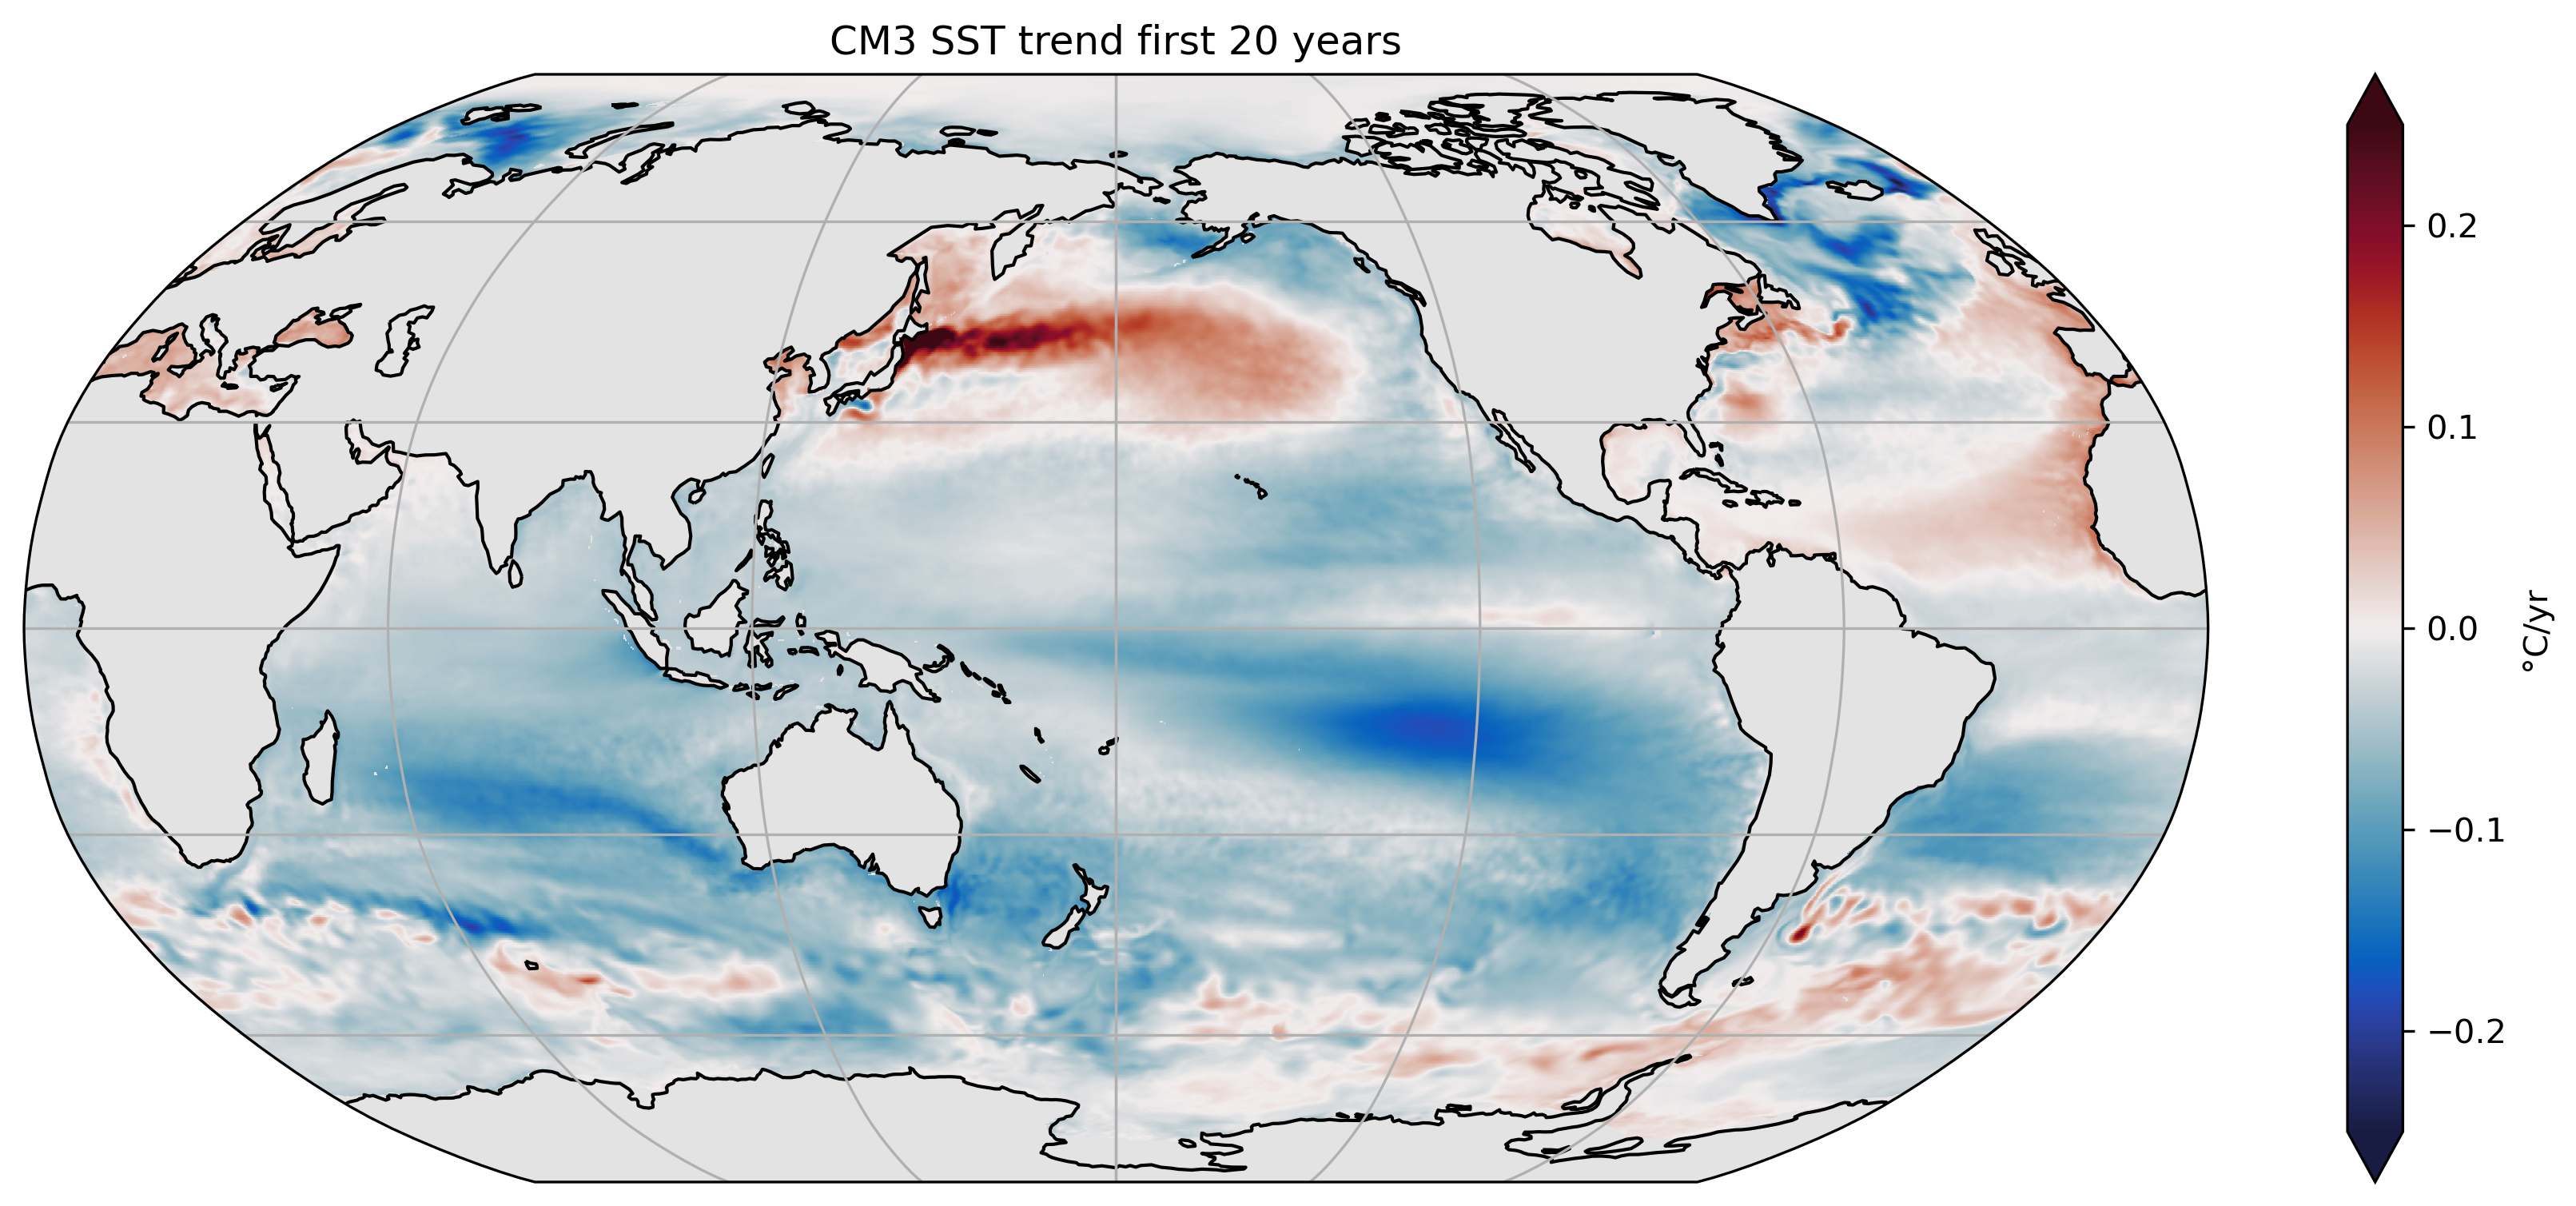

In [11]:
proj = ccrs.Robinson(central_longitude=180)
fig, ax = plt.subplots(figsize=(15,6), subplot_kw=dict(projection=proj))

sst_trend_cm3_monthly.plot(
    ax=ax, x="geolon", y="geolat", cmap=cm.cm.balance, 
    cbar_kwargs={"label": "°C/yr"}, transform=ccrs.PlateCarree(),
    vmin=-0.25, vmax=0.25
)
plt.title('CM3 SST trend first 20 years')
ax.coastlines()
_ = ax.gridlines()
mkmd.savefig(fig, "CM3 SST trend, first 20 years", "CM3 sea surface temperature trend over the first 20 years.", dpi=dpi)
